In [ ]:
## waiter tips prediction


In [ ]:

import numpy as np 
import pandas as pd

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

In [15]:
df=pd.read_csv('tips.csv')

In [16]:
df

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


<Axes: xlabel='total_bill', ylabel='tip'>

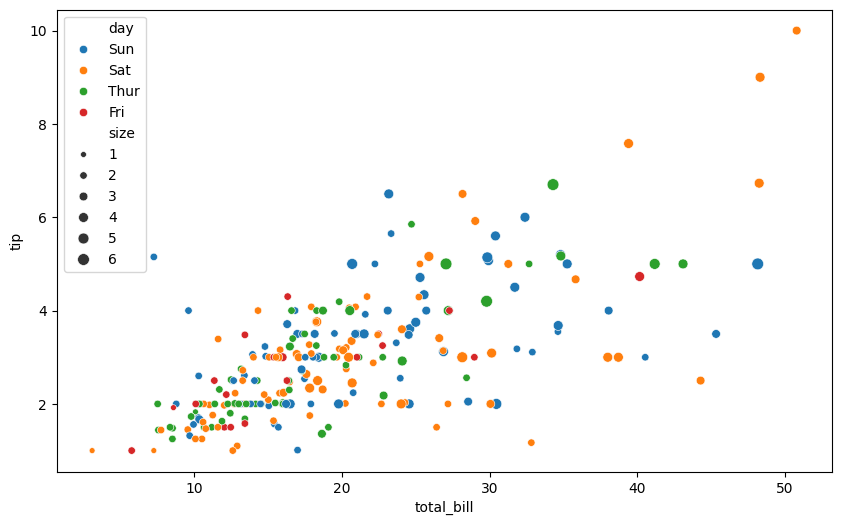

In [19]:
plt.figure(figsize=(10,6))
sns.scatterplot(x='total_bill',y='tip',size='size',data=df,hue='day')

<Axes: xlabel='total_bill', ylabel='tip'>

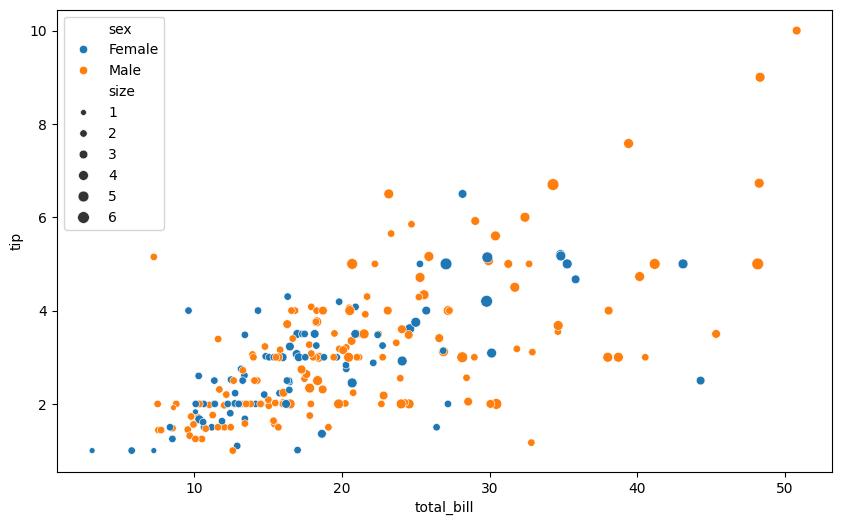

In [ ]:
plt.figure(figsize=(10,6))
sns.scatterplot(x='total_bill',y='tip',size='size',data=df,hue='sex')

<Axes: xlabel='total_bill', ylabel='tip'>

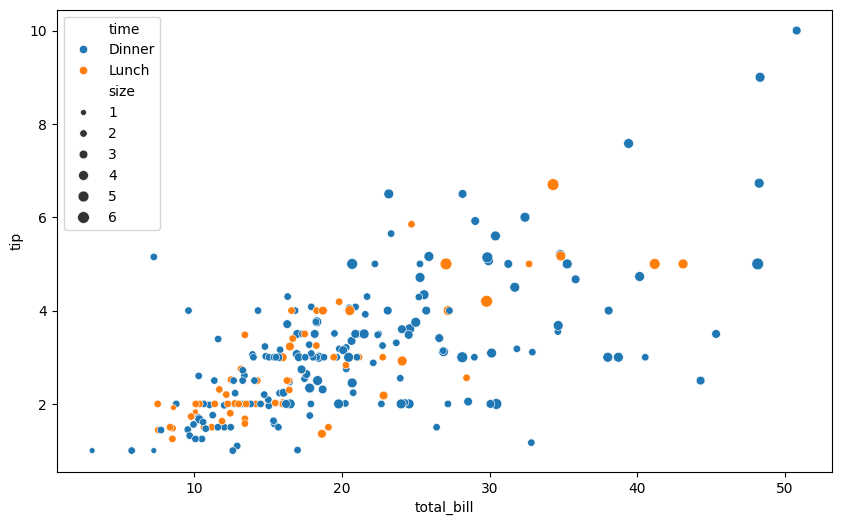

In [20]:
plt.figure(figsize=(10,6))
sns.scatterplot(x='total_bill',y='tip',size='size',data=df,hue='time',)

([<matplotlib.patches.Wedge at 0x1dc926eb230>,
 [Text(0.4790941719285186, 0.9901862321927766, 'Sun'),
  Text(-1.0967192826047463, -0.08489296297650875, 'Sat'),
  Text(0.30743429975292713, -1.0561648315179917, 'Thur'),
  Text(1.067249026516872, -0.2664198104473265, 'Fri')],
 [Text(0.2613240937791919, 0.5401015811960599, '35.7%'),
  Text(-0.598210517784407, -0.04630525253264114, '31.1%'),
  Text(0.1676914362288693, -0.5760899081007226, '25.4%'),
  Text(0.5821358326455665, -0.14531989660763261, '7.8%')])

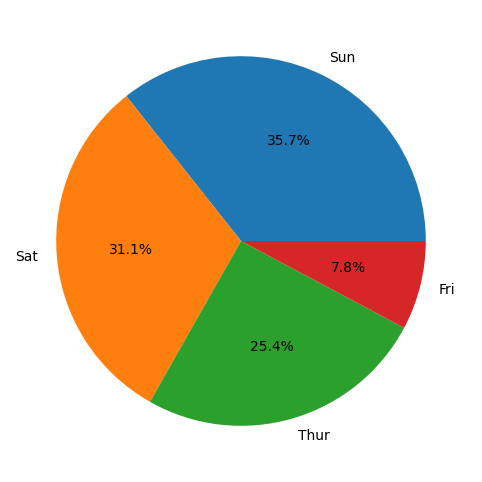

In [21]:
plt.figure(figsize=(10,6))
plt.pie(df['day'].value_counts(),labels=df['day'].unique(),autopct='%1.1f%%')

([<matplotlib.patches.Wedge at 0x1dcd4cb2350>,
 [Text(-0.47909437653273873, 0.9901861331965351, 'Female'),
  Text(0.47909422701878684, -0.990186205537762, 'Male')],
 [Text(-0.2613242053814938, 0.54010152719811, '64.3%'),
  Text(0.2613241238284292, -0.5401015666569611, '35.7%')])

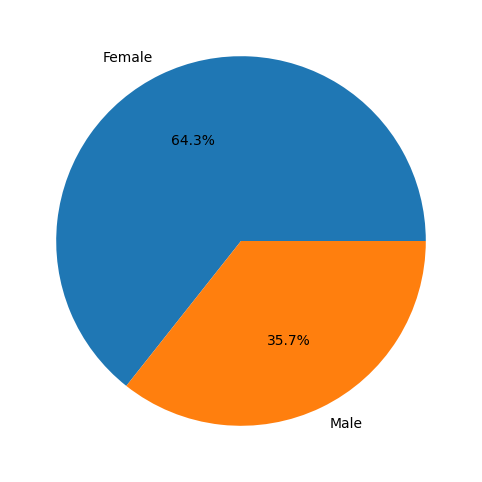

In [22]:
plt.figure(figsize=(10,6))
plt.pie(df['sex'].value_counts(),labels=df['sex'].unique(),autopct='%1.1f%%')

([<matplotlib.patches.Wedge at 0x1dcd4cf5f90>,
 [Text(-0.40124718342274707, 1.0242073509769944, 'No'),
  Text(0.40124715086677015, -1.0242073637312414, 'Yes')],
 [Text(-0.21886210004877113, 0.5586585550783606, '61.9%'),
  Text(0.21886208229096552, -0.5586585620352226, '38.1%')])

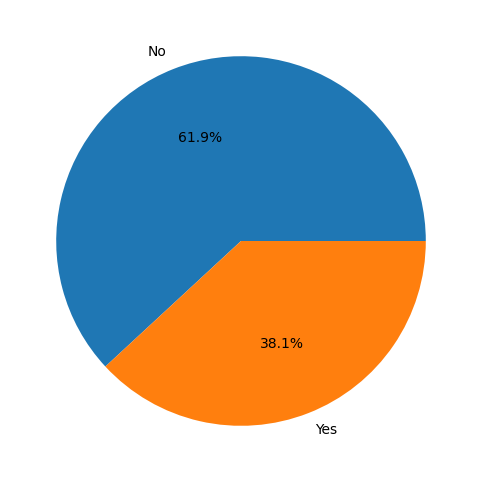

In [23]:
plt.figure(figsize=(10,6))
plt.pie(df['smoker'].value_counts(),labels=df['smoker'].unique(),autopct='%1.1f%%')

([<matplotlib.patches.Wedge at 0x1dcd48cda90>,
 [Text(-0.7046524606945154, 0.8446685205671896, 'Dinner'),
  Text(0.704652534537783, -0.8446684589645093, 'Lunch')],
 [Text(-0.38435588765155376, 0.4607282839457397, '72.1%'),
  Text(0.38435592792969975, -0.46072825034427767, '27.9%')])

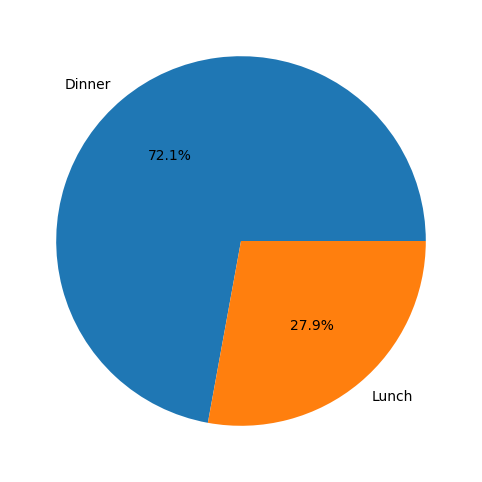

In [24]:
plt.figure(figsize=(10,6))
plt.pie(df['time'].value_counts(),labels=df['time'].unique(),autopct='%1.1f%%')

In [25]:
## waiters tips predictions model

In [26]:
df.head(10)

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
5,25.29,4.71,Male,No,Sun,Dinner,4
6,8.77,2.00,Male,No,Sun,Dinner,2
7,26.88,3.12,Male,No,Sun,Dinner,4
8,15.04,1.96,Male,No,Sun,Dinner,2
9,14.78,3.23,Male,No,Sun,Dinner,2


In [27]:
df['sex'] = df['sex'].map({'Male': 0, 'Female': 1})

df['smoker'] = df['smoker'].map({'Yes': 1, 'No': 0})

df['day'] = df['day'].map({
    'Thur': 0,
    'Fri': 1,
    'Sat': 2,
    'Sun': 3
})

df['time'] = df['time'].map({'Lunch': 0, 'Dinner': 1})

In [28]:
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,1,0,3,1,2
1,10.34,1.66,0,0,3,1,3
2,21.01,3.50,0,0,3,1,3
3,23.68,3.31,0,0,3,1,2
4,24.59,3.61,1,0,3,1,4


In [29]:
x=df[['total_bill','size','sex','smoker','day','time']]
y=df['tip']

In [30]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [31]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()

In [32]:
model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [36]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [40]:
y_pred = model.predict(x_test)
import math
import numpy as np
print("Mean Absolute Error:", mean_absolute_error(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("Root Mean Squared Error:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R2 Score:", r2_score(y_test, y_pred))

Mean Absolute Error: 0.6685728160722872
Mean Squared Error: 0.6963090766605349
Root Mean Squared Error: 0.83445136266923
R2 Score: 0.4429399687489898


In [42]:
## features = ['total_bill','size','sex','smoker','day','time']
features=np.array([[20,2,0,1,2,1]])

In [43]:
import pandas as pd

results = pd.DataFrame({
    'Actual Tip': y_test,
    'Predicted Tip': y_pred
})

print(results.head(10))

     Actual Tip  Predicted Tip
24         3.18       2.959150
6          2.00       1.979385
153        2.00       3.933555
211        5.16       3.815128
198        2.00       2.174782
176        2.00       2.659508
192        2.56       3.657512
124        2.52       2.306847
9          3.23       2.546973
101        3.00       2.270288


In [44]:
new_customer = np.array([[25.50, 3, 0, 0, 2, 1]])  # Example features for a new customer

In [45]:


predicted_tip = model.predict(new_customer)

print(f"Predicted tip: ${predicted_tip[0]:.2f}")

Predicted tip: $3.73


c:\Users\rajem\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [46]:
import joblib

joblib.dump(model, 'tip_prediction_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [47]:
model = joblib.load('tip_prediction_model.pkl')